In [2]:
import pandas as pd
import mysql.connector

from banco import conectar

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
conexao = conectar()

cursor = conexao.cursor()

cursor.execute("SHOW TABLES")

tabelas = cursor.fetchall()

for tabela in tabelas:
    print(tabela[0])

cursor.close()
conexao.close()

raw_pagamento
raw_passagem
raw_trecho
raw_viagem
silver_pagamento
silver_passagem
silver_trecho
silver_viagem


# Análise de despesas com viagens – Governo Federal (2025)

## 1. Órgãos com maior custo total

Identificar os cinco órgãos superiores que apresentaram os maiores gastos totais com viagens em 2025.

In [4]:
sql_top5 = """
SELECT
    nome_orgao_superior AS orgao,
    ROUND(SUM(valor_total), 2) AS custo_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""

conexao = conectar()
cursor = conexao.cursor()

cursor.execute(sql_top5)

resultados = cursor.fetchall()

df_top5 = pd.DataFrame(
    resultados,
    columns=["Órgão", "Custo Total (R$)"]
)

cursor.close()
conexao.close()

df_top5

,Órgão,Custo Total (R$)
0,Ministério da Justiça e Segurança Pública,486933121.65
1,Ministério da Defesa,156070304.49
2,Ministério da Educação,111291349.34
3,Ministério do Meio Ambiente e Mudança do Clima,49697710.16
4,Ministério da Previdência Social,40417309.06


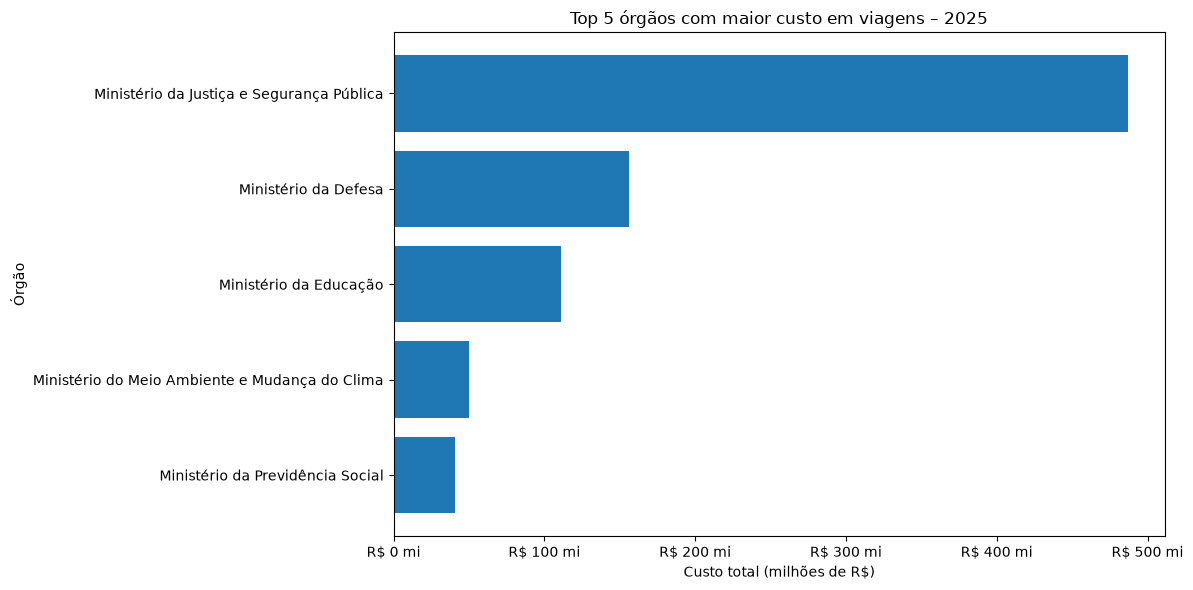

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12, 6))

plt.barh(
    df_top5["Órgão"],
    df_top5["Custo Total (R$)"]
)

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'R$ {x/1_000_000:.0f} mi')
)

plt.xlabel("Custo total (milhões de R$)")
plt.ylabel("Órgão")
plt.title("Top 5 órgãos com maior custo em viagens – 2025")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [8]:
df_top5

,Órgão,Custo Total (R$)
0,Ministério da Justiça e Segurança Pública,486933121.65
1,Ministério da Defesa,156070304.49
2,Ministério da Educação,111291349.34
3,Ministério do Meio Ambiente e Mudança do Clima,49697710.16
4,Ministério da Previdência Social,40417309.06


### Interpretação dos resultados

O Ministério da Justiça e Segurança Pública apresentou o maior custo total com viagens em 2025, atingindo aproximadamente R$ 486,9 milhões.

Em segundo lugar aparece o Ministério da Defesa, com R$ 156,1 milhões, seguido pelo Ministério da Educação, com R$ 111,3 milhões.

Observa-se uma diferença significativa entre o primeiro colocado e os demais órgãos. O Ministério da Justiça e Segurança Pública representa aproximadamente 57,7% da soma dos custos dos cinco órgãos analisados.

Esses resultados demonstram uma concentração expressiva das despesas com viagens nesse órgão.

In [9]:
conexao = conectar()

sql_destinos = """
SELECT destinos
FROM silver_viagem
WHERE destinos IS NOT NULL
LIMIT 15;
"""

df_destinos = pd.read_sql(sql_destinos, conexao)

conexao.close()

df_destinos

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\508548026.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_destinos = pd.read_sql(sql_destinos, conexao)


,destinos
0,Rio Branco/AC
1,Palmas/TO
2,"Bogotá/Colômbia, Uberlândia/MG"
3,"Londres/Reino Unido, Brasília/DF"
4,"Londres/Reino Unido, Brasília/DF"
5,"Londres/Reino Unido, Brasília/DF"
6,Palo Alto - Califórnia/Estados Unidos da América
7,Curitiba/PR
8,"Lima/Peru, Rio de Janeiro/RJ"
9,"Lima/Peru, Rio de Janeiro/RJ"


In [10]:
sql_top3_destinos = """
WITH RECURSIVE destinos_separados AS (
    SELECT
        id_viagem,
        valor_total,
        TRIM(SUBSTRING_INDEX(destinos, ',', 1)) AS destino,
        CASE
            WHEN destinos LIKE '%,%'
            THEN SUBSTRING(destinos, LOCATE(',', destinos) + 1)
            ELSE NULL
        END AS restante
    FROM silver_viagem
    WHERE destinos IS NOT NULL
      AND TRIM(destinos) <> ''

    UNION ALL

    SELECT
        id_viagem,
        valor_total,
        TRIM(SUBSTRING_INDEX(restante, ',', 1)) AS destino,
        CASE
            WHEN restante LIKE '%,%'
            THEN SUBSTRING(restante, LOCATE(',', restante) + 1)
            ELSE NULL
        END AS restante
    FROM destinos_separados
    WHERE restante IS NOT NULL
      AND TRIM(restante) <> ''
)

SELECT
    destino,
    COUNT(DISTINCT id_viagem) AS quantidade_viagens,
    ROUND(AVG(valor_total), 2) AS custo_medio
FROM destinos_separados
WHERE destino <> ''
GROUP BY destino
HAVING COUNT(DISTINCT id_viagem) >= 5
ORDER BY custo_medio DESC
LIMIT 3;
"""

conexao = conectar()

df_top3_destinos = pd.read_sql(sql_top3_destinos, conexao)

conexao.close()

df_top3_destinos

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\3220941370.py:46: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top3_destinos = pd.read_sql(sql_top3_destinos, conexao)


,destino,quantidade_viagens,custo_medio
0,Sananduva/RS,93,101128.41
1,Monte Negro/RO,96,97346.00
2,Nonoai/RS,116,92769.09


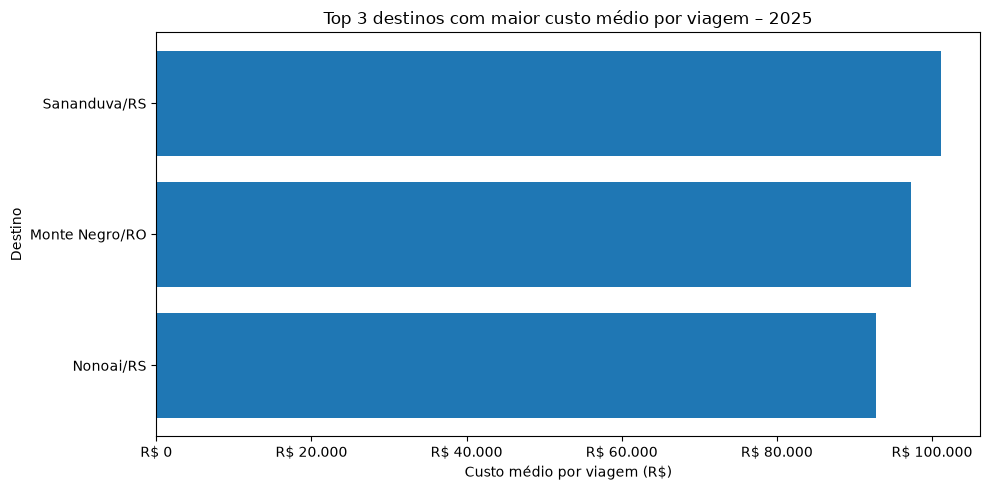

In [11]:
plt.figure(figsize=(10, 5))

plt.barh(
    df_top3_destinos["destino"],
    df_top3_destinos["custo_medio"]
)

plt.xlabel("Custo médio por viagem (R$)")
plt.ylabel("Destino")
plt.title("Top 3 destinos com maior custo médio por viagem – 2025")

plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'R$ {x:,.0f}'.replace(",", "."))
)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

Sananduva/RS apresentou o maior custo médio por viagem, com R$ 101.128,41, considerando 93 viagens distintas.

Em seguida aparece Monte Negro/RO, com custo médio de R$ 97.346,00 e 96 viagens. Nonoai/RS ficou em terceiro lugar, com média de R$ 92.769,09 e 116 viagens.

Observa-se que o destino com maior quantidade de viagens não necessariamente apresenta o maior custo médio.

A análise considera o valor total integral de cada viagem para todos os destinos associados a ela.

In [12]:
sql_viagem_mais_longa = """
SELECT
    id_viagem,
    nome_viajante,
    destinos,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagem
WHERE duracao_dias = (
    SELECT MAX(duracao_dias)
    FROM silver_viagem
    WHERE duracao_dias IS NOT NULL
);
"""

conexao = conectar()

df_viagem_mais_longa = pd.read_sql(
    sql_viagem_mais_longa,
    conexao
)

conexao.close()

df_viagem_mais_longa

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\118503117.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_viagem_mais_longa = pd.read_sql(


,id_viagem,nome_viajante,destinos,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Mogi Mirim/SP,2025-01-13,2026-01-31,383,0.0


In [13]:
sql_verificar_viagem = """
SELECT
    id_viagem,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_diarias,
    valor_passagens,
    valor_devolucao,
    valor_outros_gastos,
    valor_total
FROM silver_viagem
WHERE id_viagem = '0000000000020699856';
"""

conexao = conectar()

df_verificacao = pd.read_sql(sql_verificar_viagem, conexao)

conexao.close()

df_verificacao

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\1538839630.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_verificacao = pd.read_sql(sql_verificar_viagem, conexao)


,id_viagem,data_inicio,data_fim,duracao_dias,valor_diarias,valor_passagens,valor_devolucao,valor_outros_gastos,valor_total
0,0000000000020699856,2025-01-13,2026-01-31,383,0.0,0.0,0.0,0.0,0.0


In [29]:
sql_viagens_longas = """
SELECT
    id_viagem,
    nome_viajante,
    destinos,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagem
WHERE YEAR(data_inicio) = 2025
  AND YEAR(data_fim) = 2025
  AND duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC
LIMIT 5;
"""

conexao = conectar()

df_viagens_longas = pd.read_sql(
    sql_viagens_longas,
    conexao
)

conexao.close()

df_viagens_longas

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\335283995.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_viagens_longas = pd.read_sql(


,id_viagem,nome_viajante,destinos,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020536821,ANDRE RAPINI CLETO DA SILVA,"Brasília/DF, Belém/PA, Brasília/DF, Brasília/D...",2025-01-01,2025-12-31,364,124350.63
1,0000000000020538893,ALCEMIR COELHO DA SILVA,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC...",2025-01-01,2025-12-31,364,174064.98
2,0000000000020536724,ANA PAULA PINTO DA SILVA,"Brasília/DF, Belém/PA, Brasília/DF, Brasília/D...",2025-01-01,2025-12-31,364,134208.77
3,0000000000020540511,BRUNO LANA DE CARVALHO,"Brasília/DF, Brasília/DF, Brasília/DF, Brasíli...",2025-01-01,2025-12-31,364,126179.00
4,0000000000020536291,ALDER JOSE COSTA DE ALBUQUERQUE,"Brasília/DF, Brasília/DF, São Paulo/SP, Brasíl...",2025-01-01,2025-12-31,364,137678.63


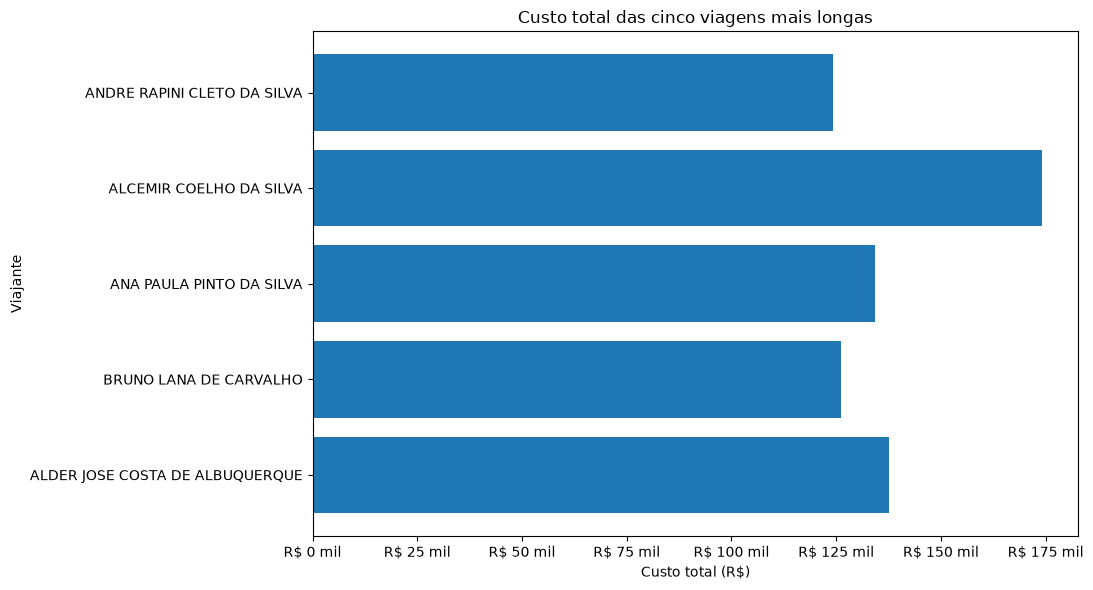

In [30]:
plt.figure(figsize=(11, 6))

plt.barh(
    df_viagens_longas["nome_viajante"],
    df_viagens_longas["valor_total"]
)

plt.title("Custo total das cinco viagens mais longas")
plt.xlabel("Custo total (R$)")
plt.ylabel("Viajante")

plt.gca().invert_yaxis()

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R$ {x / 1000:.0f} mil")
)

plt.tight_layout()
plt.show()

### Análise 3 — Viagem mais longa e seu custo total

A consulta identificou um empate entre cinco viagens com a maior duração registrada dentro do ano de 2025. Todas começaram em 01/01/2025 e terminaram em 31/12/2025, totalizando 364 dias de diferença entre as datas.

Entre essas cinco viagens, a de Alcemir Coelho da Silva apresentou o maior custo total, de R$ 174.064,98. Em seguida aparecem as viagens de Alder José Costa de Albuquerque, com R$ 137.678,63, e Ana Paula Pinto da Silva, com R$ 134.208,77.

Os resultados demonstram que as viagens mais longas tiveram custos diferentes, apesar de apresentarem a mesma duração.

In [15]:
sql_gold = """
CREATE OR REPLACE VIEW vw_gold_resumo_orgao AS

WITH pagamentos AS (
    SELECT
        id_viagem,
        SUM(valor) AS total_pagamentos
    FROM silver_pagamento
    GROUP BY id_viagem
),

passagens AS (
    SELECT
        id_viagem,
        COUNT(*) AS quantidade_passagens
    FROM silver_passagem
    GROUP BY id_viagem
),

trechos AS (
    SELECT
        id_viagem,
        COUNT(*) AS quantidade_trechos
    FROM silver_trecho
    GROUP BY id_viagem
)

SELECT
    v.nome_orgao_superior,

    COUNT(DISTINCT v.id_viagem) AS quantidade_viagens,

    ROUND(SUM(v.valor_total), 2) AS custo_total,

    ROUND(AVG(v.valor_total), 2) AS custo_medio,

    ROUND(SUM(COALESCE(p.total_pagamentos, 0)), 2)
        AS total_pagamentos,

    SUM(COALESCE(pa.quantidade_passagens, 0))
        AS quantidade_passagens,

    SUM(COALESCE(t.quantidade_trechos, 0))
        AS quantidade_trechos

FROM silver_viagem v

LEFT JOIN pagamentos p
    ON v.id_viagem = p.id_viagem

LEFT JOIN passagens pa
    ON v.id_viagem = pa.id_viagem

LEFT JOIN trechos t
    ON v.id_viagem = t.id_viagem

GROUP BY v.nome_orgao_superior;
"""

conexao = conectar()
cursor = conexao.cursor()

cursor.execute(sql_gold)

conexao.commit()

cursor.close()
conexao.close()

print("VIEW Gold criada com sucesso!")

VIEW Gold criada com sucesso!


In [17]:
conexao = conectar()

df_gold = pd.read_sql(
    "SELECT * FROM gold_resumo_orgao ORDER BY custo_total DESC;",
    conexao
)

conexao.close()

df_gold

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\3355755023.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_gold = pd.read_sql(


,nome_orgao_superior,quantidade_viagens,custo_total,custo_medio,total_pagamentos,quantidade_passagens,quantidade_trechos
0,Ministério da Justiça e Segurança Pública,75742,4.869331e+08,6428.84,4.888311e+08,7430.0,95096.0
1,Ministério da Defesa,61912,1.560703e+08,2520.84,1.565498e+08,38038.0,161823.0
2,Ministério da Educação,65295,1.112913e+08,1704.44,1.118974e+08,29981.0,152531.0
3,Ministério do Meio Ambiente e Mudança do Clima,19413,4.969771e+07,2560.02,5.012304e+07,8917.0,58363.0
4,Ministério da Previdência Social,8190,4.041731e+07,4934.96,4.065949e+07,4293.0,21477.0
5,Ministério da Saúde,8672,3.904983e+07,4502.98,3.951792e+07,9883.0,21061.0
6,Ministério da Fazenda,11854,3.247439e+07,2739.53,3.266602e+07,8572.0,25109.0
7,Ministério dos Povos Indígenas,5101,2.628692e+07,5153.29,2.644114e+07,2903.0,14229.0
8,Ministério das Relações Exteriores,2014,2.553355e+07,12678.03,2.572434e+07,2478.0,3974.0
9,Ministério do Desenvolvimento Agrário e Agricu...,8581,2.199842e+07,2563.62,2.217168e+07,4817.0,23030.0


In [18]:
sql_validar_gold = """
SELECT
    (SELECT COUNT(*) FROM gold_resumo_orgao)
        AS total_linhas_gold,

    (SELECT COUNT(*) FROM vw_gold_resumo_orgao)
        AS total_linhas_view,

    (SELECT COUNT(DISTINCT nome_orgao_superior)
     FROM gold_resumo_orgao)
        AS orgaos_distintos,

    (SELECT ROUND(SUM(custo_total), 2)
     FROM gold_resumo_orgao)
        AS custo_gold,

    (SELECT ROUND(SUM(valor_total), 2)
     FROM silver_viagem)
        AS custo_silver,

    (SELECT ROUND(SUM(total_pagamentos), 2)
     FROM gold_resumo_orgao)
        AS pagamentos_gold,

    (SELECT ROUND(SUM(valor), 2)
     FROM silver_pagamento)
        AS pagamentos_silver;
"""

conexao = conectar()

df_validacao_gold = pd.read_sql(sql_validar_gold, conexao)

conexao.close()

df_validacao_gold

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\3369819024.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_validacao_gold = pd.read_sql(sql_validar_gold, conexao)


,total_linhas_gold,total_linhas_view,orgaos_distintos,custo_gold,custo_silver,pagamentos_gold,pagamentos_silver
0,35,35,35,1.188145e+09,1.188145e+09,1.194365e+09,1.194365e+09


In [19]:
sql_pagamentos = """
SELECT
    tipo_pagamento,
    COUNT(*) AS quantidade_pagamentos,
    ROUND(AVG(valor), 2) AS valor_medio,
    ROUND(SUM(valor), 2) AS valor_total
FROM silver_pagamento
WHERE valor IS NOT NULL
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC;
"""

conexao = conectar()

df_pagamentos = pd.read_sql(sql_pagamentos, conexao)

conexao.close()

df_pagamentos

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\1529786921.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pagamentos = pd.read_sql(sql_pagamentos, conexao)


,tipo_pagamento,quantidade_pagamentos,valor_medio,valor_total
0,DIÁRIAS,401463,2078.28,8.343526e+08
1,PASSAGEM,188985,1878.34,3.549789e+08
2,Serviço correlato: seguro,4894,447.51,2.190137e+06
3,RESTITUIÇÃO,11574,245.70,2.843762e+06


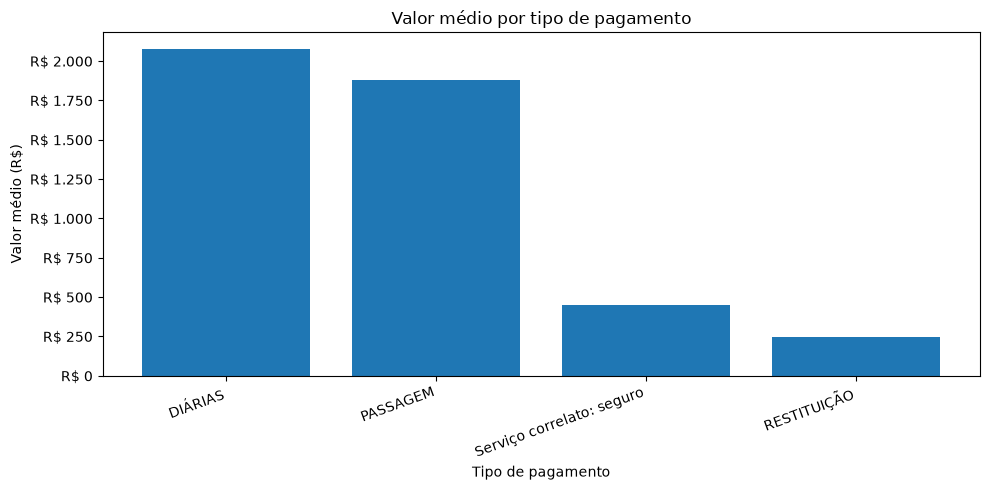

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(
    df_pagamentos["tipo_pagamento"],
    df_pagamentos["valor_medio"]
)

plt.title("Valor médio por tipo de pagamento")
plt.xlabel("Tipo de pagamento")
plt.ylabel("Valor médio (R$)")

plt.xticks(rotation=20, ha="right")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R$ {x:,.0f}".replace(",", "."))
)

plt.tight_layout()
plt.show()

### Análise 4 — Tipo de pagamento com maior valor médio

A análise demonstrou que a categoria **DIÁRIAS** apresenta o maior valor médio por pagamento, totalizando R$ 2.078,28. Em seguida, aparecem as passagens, com média de R$ 1.878,34.

As diárias também representam a maior quantidade de registros, com 401.463 pagamentos, enquanto as passagens somam 188.985 registros.

Os resultados indicam que as diárias possuem maior representatividade tanto na quantidade de pagamentos quanto no valor médio.

In [21]:
sql_transportes = """
SELECT
    meio_transporte,
    COUNT(*) AS quantidade_trechos
FROM silver_trecho
WHERE meio_transporte IS NOT NULL
  AND TRIM(meio_transporte) <> ''
GROUP BY meio_transporte
ORDER BY quantidade_trechos DESC;
"""

conexao = conectar()

df_transportes = pd.read_sql(sql_transportes, conexao)

conexao.close()

df_transportes

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\1129913136.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_transportes = pd.read_sql(sql_transportes, conexao)


,meio_transporte,quantidade_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


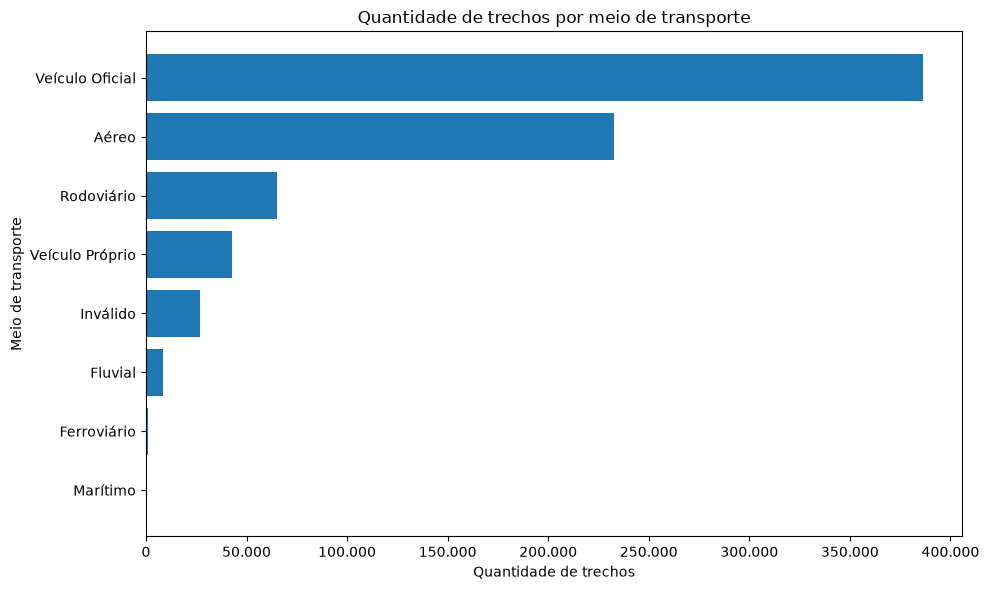

In [22]:
plt.figure(figsize=(10, 6))

plt.barh(
    df_transportes["meio_transporte"],
    df_transportes["quantidade_trechos"]
)

plt.title("Quantidade de trechos por meio de transporte")
plt.xlabel("Quantidade de trechos")
plt.ylabel("Meio de transporte")

plt.gca().invert_yaxis()

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", "."))
)

plt.tight_layout()
plt.show()

### Análise 5 — Meio de transporte mais utilizado

O levantamento demonstrou que o **Veículo Oficial** é o meio de transporte mais utilizado, com 386.424 trechos registrados. Em segundo lugar está o transporte Aéreo, com 232.666 registros.

O transporte Rodoviário aparece na terceira posição, com 64.970 trechos.

Também foram identificados 26.659 registros classificados como "Inválido", indicando a existência de informações que merecem atenção em relação à qualidade dos dados.

Os resultados demonstram a predominância do uso de veículos oficiais nos deslocamentos registrados.

In [23]:
sql_destinos_uf = """
SELECT
    destino_uf,
    COUNT(*) AS quantidade_trechos
FROM silver_trecho
WHERE destino_uf IS NOT NULL
  AND TRIM(destino_uf) <> ''
GROUP BY destino_uf
ORDER BY quantidade_trechos DESC
LIMIT 10;
"""

conexao = conectar()

df_destinos_uf = pd.read_sql(sql_destinos_uf, conexao)

conexao.close()

df_destinos_uf

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\1308647771.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_destinos_uf = pd.read_sql(sql_destinos_uf, conexao)


,destino_uf,quantidade_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


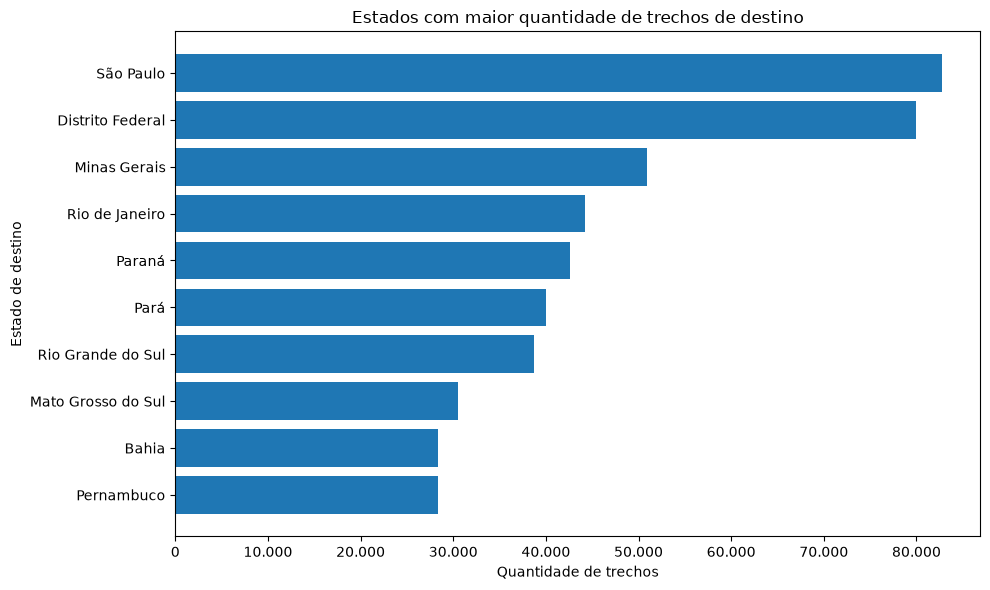

In [24]:
plt.figure(figsize=(10, 6))

plt.barh(
    df_destinos_uf["destino_uf"],
    df_destinos_uf["quantidade_trechos"]
)

plt.title("Estados com maior quantidade de trechos de destino")
plt.xlabel("Quantidade de trechos")
plt.ylabel("Estado de destino")

plt.gca().invert_yaxis()

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", "."))
)

plt.tight_layout()
plt.show()

### Análise 6 — UF de destino com maior quantidade de trechos

São Paulo foi o estado que apresentou a maior quantidade de trechos com destino registrado, totalizando 82.722 ocorrências. Em seguida aparece o Distrito Federal, com 79.962 registros.

Minas Gerais ocupa a terceira posição, com 50.965 trechos, seguido pelo Rio de Janeiro, com 44.197.

Os resultados demonstram uma concentração dos deslocamentos registrados principalmente em São Paulo e no Distrito Federal.

In [25]:
sql_orgao_pagador = """
SELECT
    nome_orgao_pagador,
    COUNT(*) AS quantidade_pagamentos,
    ROUND(SUM(valor), 2) AS total_pago
FROM silver_pagamento
WHERE nome_orgao_pagador IS NOT NULL
  AND TRIM(nome_orgao_pagador) <> ''
GROUP BY nome_orgao_pagador
ORDER BY total_pago DESC
LIMIT 10;
"""

conexao = conectar()

df_orgao_pagador = pd.read_sql(sql_orgao_pagador, conexao)

conexao.close()

df_orgao_pagador

C:\Users\Bruna\AppData\Local\Temp\ipykernel_13164\2520996225.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_orgao_pagador = pd.read_sql(sql_orgao_pagador, conexao)


,nome_orgao_pagador,quantidade_pagamentos,total_pago
0,Fundo Nacional de Segurança Pública,79816,2.784810e+08
1,Sigiloso,93141,2.004848e+08
2,Comando da Aeronáutica,46193,8.176914e+07
3,Instituto Nacional do Seguro Social,18324,3.742760e+07
4,Comando do Exército,22837,3.687264e+07
5,Ministério da Gestão e da Inovação em Serviços...,20291,3.554176e+07
6,Instituto Brasileiro do Meio Ambiente e dos Re...,16758,3.158985e+07
7,Ministério das Relações Exteriores - Unidades ...,3705,2.560538e+07
8,Receita Federal do Brasil,18917,2.381103e+07
9,Ministério da Agricultura e Pecuária - Unidade...,15864,2.289988e+07


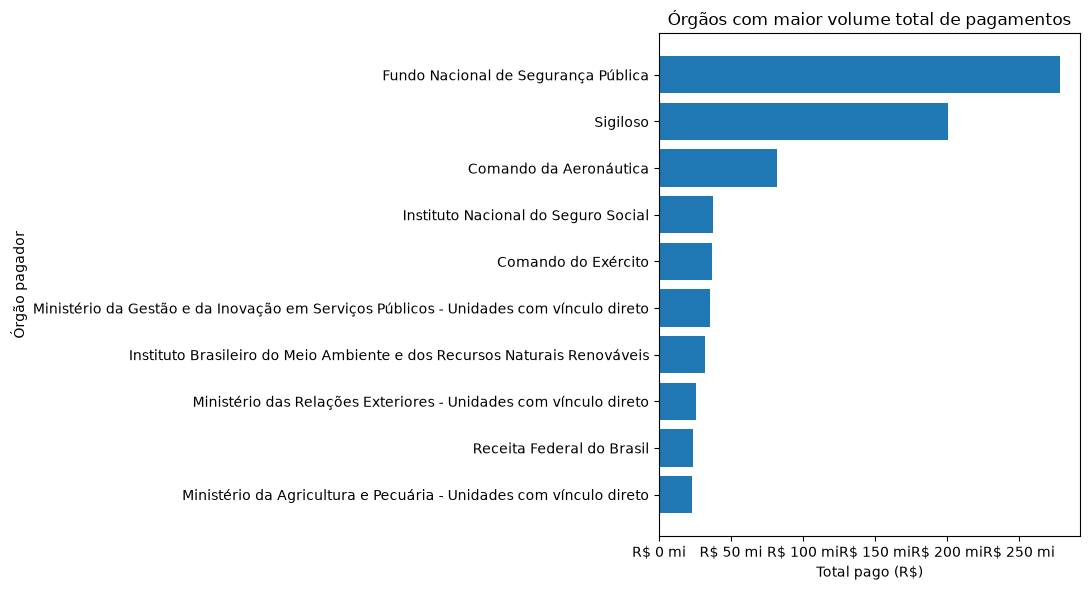

In [26]:
plt.figure(figsize=(11, 6))

plt.barh(
    df_orgao_pagador["nome_orgao_pagador"],
    df_orgao_pagador["total_pago"]
)

plt.title("Órgãos com maior volume total de pagamentos")
plt.xlabel("Total pago (R$)")
plt.ylabel("Órgão pagador")

plt.gca().invert_yaxis()

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"R$ {x / 1_000_000:.0f} mi"
    )
)

plt.tight_layout()
plt.show()

### Análise 7 — Órgão com maior volume total de pagamentos

O Fundo Nacional de Segurança Pública apresentou o maior volume financeiro entre os órgãos pagadores, totalizando aproximadamente R$ 278,48 milhões, distribuídos em 79.816 pagamentos.

Em segundo lugar aparece a categoria "Sigiloso", com aproximadamente R$ 200,48 milhões e 93.141 pagamentos. Como essa identificação é apresentada de forma sigilosa na base, não é possível determinar o órgão correspondente.

Entre os demais órgãos identificados, destacam-se o Comando da Aeronáutica, com aproximadamente R$ 81,77 milhões, e o Instituto Nacional do Seguro Social, com aproximadamente R$ 37,43 milhões.

Os resultados demonstram que o Fundo Nacional de Segurança Pública concentrou o maior volume financeiro de pagamentos entre os órgãos identificados.